# Laboratorul 1 - Procesare Big Data

## Etapa 1: Alegerea dataset-ului

În această etapă vom analiza datasetul ales pentru procesare big data.

In [2]:
import os
import warnings
from importlib.metadata import PackageNotFoundError, version


def installed_version(package_name):
    try:
        return version(package_name)
    except PackageNotFoundError:
        return 'not installed'


spark_package_version = installed_version('pyspark')
delta_package_version = installed_version('delta-spark')
if not (spark_package_version.startswith('4.2.') and delta_package_version.startswith('4.4.')):
    message = (
        f'Runtime-ul Codespaces cere PySpark 4.2.x și Delta 4.4.x; '
        f'aici sunt instalate PySpark {spark_package_version} și Delta {delta_package_version}.'
    )
    if os.environ.get('CODESPACES', '').lower() == 'true':
        raise RuntimeError(message)
    warnings.warn(message, stacklevel=1)
print(f'Runtime: PySpark {spark_package_version}, Delta {delta_package_version}')

Runtime: PySpark 4.2.0, Delta 4.4.0


In [3]:
# Import librării necesare
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql.types import *
import warnings
warnings.filterwarnings('ignore')

# Configurare vizualizări
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
%matplotlib inline

In [4]:
from pathlib import Path

current_directory = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in (current_directory, *current_directory.parents)
        if (candidate / 'Laboratorul 1.ipynb').is_file()
    ),
    current_directory,
)
print(f'Rădăcina proiectului: {PROJECT_ROOT}')

Rădăcina proiectului: /workspaces/PBC-Lab-1


In [5]:
import csv
import os
from pathlib import Path

PROJECT_ROOT = Path(PROJECT_ROOT).resolve()
DATA_ROOT = PROJECT_ROOT / 'data'
RAW_DIR = DATA_ROOT / 'raw'
RAW_DIR.mkdir(parents=True, exist_ok=True)

dataset_name = 'Crimes_-_2001_to_Present_20260925.csv'
file_path_object = RAW_DIR / dataset_name
file_path = str(file_path_object)
dataset_url = "https://drive.google.com/file/d/1xUBbjByfle-cRvzXJjisjtSimtuFzRP-/view?usp=sharing" #os.environ.get('DATASET_URL', '').strip()
minimum_dataset_bytes = 2 * (1024 ** 3)

if not file_path_object.is_file():
    if not dataset_url:
        raise RuntimeError(
            f'CSV-ul lipsește din {RAW_DIR}. Setați variabila DATASET_URL la '
            'linkul public Google Drive înainte de a rula notebookul.'
        )

    import gdown

    temporary_path = file_path_object.with_suffix(file_path_object.suffix + '.part')
    temporary_path.unlink(missing_ok=True)
    downloaded_path = gdown.download(
        url=dataset_url,
        output=str(temporary_path),
        quiet=False,
        fuzzy=True,
    )
    if not downloaded_path or not temporary_path.is_file():
        raise RuntimeError('Descărcarea CSV-ului a eșuat; verificați accesul public la link.')

    temporary_size = temporary_path.stat().st_size
    if temporary_size < minimum_dataset_bytes:
        raise ValueError(
            f'Dataset-ul descărcat are {temporary_size:,} bytes; sunt necesari minimum 2 GiB.'
        )
    with temporary_path.open('r', encoding='utf-8-sig', newline='') as csv_file:
        header = next(csv.reader(csv_file), [])
    if not {'ID', 'Case Number', 'Date'}.issubset(header):
        raise ValueError('Fișierul descărcat nu pare a fi CSV-ul Chicago Crimes așteptat.')
    temporary_path.replace(file_path_object)

file_size = file_path_object.stat().st_size
if file_size < minimum_dataset_bytes:
    raise ValueError(f'Dataset-ul trebuie să aibă minimum 2 GiB; are {file_size:,} bytes.')
with file_path_object.open('r', encoding='utf-8-sig', newline='') as csv_file:
    source_header = next(csv.reader(csv_file), [])
if not {'ID', 'Case Number', 'Date'}.issubset(source_header):
    raise ValueError(f'Header CSV neașteptat în {file_path}.')

print(f'Fișier sursă: {file_path}')
print(f'Dimensiune fișier: {file_size / (1024 ** 3):.2f} GiB')

Fișier sursă: /workspaces/PBC-Lab-1/data/raw/Crimes_-_2001_to_Present_20260925.csv
Dimensiune fișier: 2.24 GiB


In [6]:
# Citire primele 10 rânduri pentru a înțelege structura
try:
    df_sample = pd.read_csv(file_path, nrows=10)
    print("Coloanele din dataset:")
    print(df_sample.columns.tolist())
    print("\nPrimele 10 rânduri:")
    print(df_sample)
    print("\nTipuri de date:")
    print(df_sample.dtypes)
except Exception as e:
    print(f"Eroare la citirea fișierului: {e}")

Coloanele din dataset:
['ID', 'Case Number', 'Date', 'Block', 'IUCR', 'Primary Type', 'Description', 'Location Description', 'Arrest', 'Domestic', 'Beat', 'District', 'Ward', 'Community Area', 'FBI Code', 'X Coordinate', 'Y Coordinate', 'Year', 'Updated On', 'Latitude', 'Longitude', 'Location']

Primele 10 rânduri:
         ID Case Number                    Date  \
0  14329936    JK415994  09/16/2026 12:00:00 AM   
1  14332840    JK419513  09/16/2026 12:00:00 AM   
2  14329074    JK414859  09/16/2026 12:00:00 AM   
3  14329468    JK415287  09/16/2026 12:00:00 AM   
4  14330539    JK416884  09/16/2026 12:00:00 AM   
5  14329575    JK415610  09/16/2026 12:00:00 AM   
6  14336390    JK423947  09/16/2026 12:00:00 AM   
7  14329284    JK415110  09/16/2026 12:00:00 AM   
8  14333202    JK420095  09/16/2026 12:00:00 AM   
9  14330639    JK416997  09/16/2026 12:00:00 AM   

                                 Block  IUCR         Primary Type  \
0                  048XX N KIMBALL AVE   486        

## Descrierea dataset-ului

**Link către datasetul original:** [Crimes - 2001 to Present | City of Chicago | Data Portal](https://data.cityofchicago.org/Public-Safety/Crimes-2001-to-Present/ijzp-q8t2/about_data)

Datasetul conține informații despre infracțiunile raportate în Chicago de la 2001 până în prezent. Acesta include detalii precum data și ora infracțiunii, tipul de crimă, locația, districtul de poliție și alte informații relevante.

Am ales acest dataset pentru că:
1. Are dimensiunea corespunzătoare cerințelor (peste 2GB)
2. Conține date temporale (timestamp-uri) utile pentru analize ulterioare
3. Este un exemplu realist de date de tip Big Data
4. Oferă oportunități de analiză și procesare complexă

## Etapa 2: Ingestie și stocare

În această etapă inițializăm Spark cu Delta Lake și încărcăm CSV-ul cu o schemă declarată explicit. Comparația formatelor și scrierile de stocare sunt realizate separat în etapa dedicată.

In [7]:
# Inițializare Spark cu Delta Lake și connectorul Structured Streaming pentru Kafka.
from delta import configure_spark_with_delta_pip
from delta.tables import DeltaTable

KAFKA_SPARK_PACKAGE = 'org.apache.spark:spark-sql-kafka-0-10_2.13:4.2.0'
builder = (
    SparkSession.builder
    .appName('Chicago_Crimes_Analysis')
    .config('spark.sql.adaptive.enabled', 'true')
    .config('spark.sql.adaptive.coalescePartitions.enabled', 'true')
    .config('spark.sql.session.timeZone', 'UTC')
    .config('spark.sql.extensions', 'io.delta.sql.DeltaSparkSessionExtension')
    .config('spark.sql.catalog.spark_catalog', 'org.apache.spark.sql.delta.catalog.DeltaCatalog')
)
spark = configure_spark_with_delta_pip(
    builder,
    extra_packages=[KAFKA_SPARK_PACKAGE],
).getOrCreate()
print(f'Sesiune PySpark inițializată: Spark {spark.version}')

:: loading settings :: url = jar:file:/usr/local/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /home/vscode/.ivy2.5.2/cache
The jars for the packages stored in: /home/vscode/.ivy2.5.2/jars
io.delta#delta-spark_4.2_2.13 added as a dependency
org.apache.spark#spark-sql-kafka-0-10_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-af02d7fc-cccf-4bba-b491-495bc353f424;1.0
	confs: [default]
	found io.delta#delta-spark_4.2_2.13;4.4.0 in central
	found io.delta#delta-storage;4.4.0 in central
	found io.unitycatalog#unitycatalog-client;0.6.0 in central
	found org.slf4j#slf4j-api;2.0.13 in central
	found org.apache.logging.log4j#log4j-slf4j2-impl;2.25.3 in central
	found org.apache.logging.log4j#log4j-api;2.25.3 in central
	found com.google.code.findbugs#jsr305;3.0.2 in central
	found io.unitycatalog#unitycatalog-hadoop;0.6.0 in central
	found org.apache.logging.log4j#log4j

Sesiune PySpark inițializată: Spark 4.2.0


In [8]:
# Schema explicită pentru CSV; identificatorii și codurile rămân șiruri când zerourile inițiale contează.
crime_schema = StructType([
    StructField('ID', LongType(), True),
    StructField('Case Number', StringType(), True),
    StructField('Date', StringType(), True),
    StructField('Block', StringType(), True),
    StructField('IUCR', StringType(), True),
    StructField('Primary Type', StringType(), True),
    StructField('Description', StringType(), True),
    StructField('Location Description', StringType(), True),
    StructField('Arrest', BooleanType(), True),
    StructField('Domestic', BooleanType(), True),
    StructField('Beat', StringType(), True),
    StructField('District', StringType(), True),
    StructField('Ward', IntegerType(), True),
    StructField('Community Area', IntegerType(), True),
    StructField('FBI Code', StringType(), True),
    StructField('X Coordinate', DoubleType(), True),
    StructField('Y Coordinate', DoubleType(), True),
    StructField('Year', IntegerType(), True),
    StructField('Updated On', StringType(), True),
    StructField('Latitude', StringType(), True),
    StructField('Longitude', StringType(), True),
    StructField('Location', StringType(), True),
])

def read_source_csv(path):
    raw_df = (
        spark.read.schema(crime_schema)
        .option('header', 'true')
        .option('mode', 'FAILFAST')
        .csv(path)
    )
    return (
        raw_df
        .withColumn('Date', to_timestamp(col('Date'), 'MM/dd/yyyy hh:mm:ss a'))
        .withColumn('Updated On', to_timestamp(col('Updated On'), 'MM/dd/yyyy hh:mm:ss a'))
        .withColumn('Latitude', regexp_replace(col('Latitude'), ',', '.').cast(DoubleType()))
        .withColumn('Longitude', regexp_replace(col('Longitude'), ',', '.').cast(DoubleType()))
    )

crimes_df = read_source_csv(file_path)
print(f'Număr total de înregistrări: {crimes_df.count()}')
print(f'Număr coloane: {len(crimes_df.columns)}')
crimes_df.printSchema()

Număr total de înregistrări: 8645530
Număr coloane: 22
root
 |-- ID: long (nullable = true)
 |-- Case Number: string (nullable = true)
 |-- Date: timestamp (nullable = true)
 |-- Block: string (nullable = true)
 |-- IUCR: string (nullable = true)
 |-- Primary Type: string (nullable = true)
 |-- Description: string (nullable = true)
 |-- Location Description: string (nullable = true)
 |-- Arrest: boolean (nullable = true)
 |-- Domestic: boolean (nullable = true)
 |-- Beat: string (nullable = true)
 |-- District: string (nullable = true)
 |-- Ward: integer (nullable = true)
 |-- Community Area: integer (nullable = true)
 |-- FBI Code: string (nullable = true)
 |-- X Coordinate: double (nullable = true)
 |-- Y Coordinate: double (nullable = true)
 |-- Year: integer (nullable = true)
 |-- Updated On: timestamp (nullable = true)
 |-- Latitude: double (nullable = true)
 |-- Longitude: double (nullable = true)
 |-- Location: string (nullable = true)



In [9]:
# Afișare primele 5 rânduri
crimes_df.show(5)

+--------+-----------+-------------------+-------------------+----+------------+--------------------+--------------------+------+--------+----+--------+----+--------------+--------+------------+------------+----+-------------------+------------+-------------+--------------------+
|      ID|Case Number|               Date|              Block|IUCR|Primary Type|         Description|Location Description|Arrest|Domestic|Beat|District|Ward|Community Area|FBI Code|X Coordinate|Y Coordinate|Year|         Updated On|    Latitude|    Longitude|            Location|
+--------+-----------+-------------------+-------------------+----+------------+--------------------+--------------------+------+--------+----+--------+----+--------------+--------+------------+------------+----+-------------------+------------+-------------+--------------------+
|14329936|   JK415994|2026-09-16 00:00:00|048XX N KIMBALL AVE|0486|     BATTERY|DOMESTIC BATTERY ...|               ALLEY| false|    true|1712|     017|  33|

In [10]:
# Păstrăm DataFrame-ul sursă nemodificat pentru curățare și comparații.
crimes_df.show(5, truncate=False)

+--------+-----------+-------------------+-------------------+----+------------+---------------------------+--------------------+------+--------+----+--------+----+--------------+--------+------------+------------+----+-------------------+------------+-------------+-----------------------------+
|ID      |Case Number|Date               |Block              |IUCR|Primary Type|Description                |Location Description|Arrest|Domestic|Beat|District|Ward|Community Area|FBI Code|X Coordinate|Y Coordinate|Year|Updated On         |Latitude    |Longitude    |Location                     |
+--------+-----------+-------------------+-------------------+----+------------+---------------------------+--------------------+------+--------+----+--------+----+--------------+--------+------------+------------+----+-------------------+------------+-------------+-----------------------------+
|14329936|JK415994   |2026-09-16 00:00:00|048XX N KIMBALL AVE|0486|BATTERY     |DOMESTIC BATTERY SIMPLE    |A

### Beneficiile utilizării Delta Lake față de Parquet simplu:

1. **ACID Transactions**: Asigură consistența datelor prin tranzacții ACID, permițând operatii concurente fără coruperea datelor.
2. **Schema Evolution**: Permite adăugarea sau modificarea coloanelor fără recrearea întregii baze de date.
3. **Time Travel**: Posibilitatea de a accesa versiuni anterioare ale datelor pentru audit sau recuperare.
4. **Optimizare automată**: Compacțare și clustering automat pentru performanță crescută.
5. **Upserts și deletes**: Suport nativ pentru operații de tip upsert (merge) și ștergere.
6. **Audit trail**: Jurnal complet al tuturor modificărilor efectuate asupra datelor.
7. **Compatibilitate cu Apache Spark**: Integrare perfectă cu ecosistemul Spark.

## Etapa 3: Curățare și transformare

În această etapă vom curăța datele, vom converti tipurile de date și vom face agregări simple.

In [11]:
# Verificare valori lipsă
print('Numărul valorilor nule sau goale pe coloană:')
null_counts = crimes_df.select([
    sum(when(col(column_name).isNull() | (col(column_name).cast('string') == ''), 1).otherwise(0))
    .alias(column_name)
    for column_name in crimes_df.columns
])
null_counts.show(truncate=False)

Numărul valorilor nule sau goale pe coloană:


+---+-----------+----+-----+----+------------+-----------+--------------------+------+--------+----+--------+------+--------------+--------+------------+------------+----+----------+--------+---------+--------+
|ID |Case Number|Date|Block|IUCR|Primary Type|Description|Location Description|Arrest|Domestic|Beat|District|Ward  |Community Area|FBI Code|X Coordinate|Y Coordinate|Year|Updated On|Latitude|Longitude|Location|
+---+-----------+----+-----+----+------------+-----------+--------------------+------+--------+----+--------+------+--------------+--------+------------+------------+----+----------+--------+---------+--------+
|0  |0          |0   |0    |0   |0           |0          |16699               |0     |0       |0   |47      |614811|613722        |0       |100091      |100091      |0   |0         |100091  |100091   |100091  |
+---+-----------+----+-----+----+------------+-----------+--------------------+------+--------+----+--------+------+--------------+--------+------------+---

In [12]:
# Alternativă pentru verificarea valorilor lipsă
null_counts = crimes_df.select([count(when(col(c).isNull(), c)).alias(c) for c in crimes_df.columns])
null_counts.show()

+---+-----------+----+-----+----+------------+-----------+--------------------+------+--------+----+--------+------+--------------+--------+------------+------------+----+----------+--------+---------+--------+
| ID|Case Number|Date|Block|IUCR|Primary Type|Description|Location Description|Arrest|Domestic|Beat|District|  Ward|Community Area|FBI Code|X Coordinate|Y Coordinate|Year|Updated On|Latitude|Longitude|Location|
+---+-----------+----+-----+----+------------+-----------+--------------------+------+--------+----+--------+------+--------------+--------+------------+------------+----+----------+--------+---------+--------+
|  0|          0|   0|    0|   0|           0|          0|               16699|     0|       0|   0|      47|614811|        613722|       0|      100091|      100091|   0|         0|  100091|   100091|  100091|
+---+-----------+----+-----+----+------------+-----------+--------------------+------+--------+----+--------+------+--------------+--------+------------+---

In [13]:
# Conversia tipurilor de date - în special pentru coloanele de timp
# Vom presupune că există o coloană de tip dată (de exemplu, 'Date')
# Vom verifica coloanele care ar putea conține date/timp

# Afișare statistici descriptive pentru coloanele numerice
numeric_cols = []
for field in crimes_df.schema.fields:
    if isinstance(field.dataType, (IntegerType, LongType, FloatType, DoubleType)):
        numeric_cols.append(field.name)

if numeric_cols:
    print("Statistici descriptive pentru coloanele numerice:")
    crimes_df.select(numeric_cols).describe().show()
else:
    print("Nu s-au găsit coloane numerice în dataset.")

Statistici descriptive pentru coloanele numerice:


26/10/09 09:07:24 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+------------------+------------------+------------------+------------------+-----------------+------------------+-------------------+-------------------+
|summary|                ID|              Ward|    Community Area|      X Coordinate|     Y Coordinate|              Year|           Latitude|          Longitude|
+-------+------------------+------------------+------------------+------------------+-----------------+------------------+-------------------+-------------------+
|  count|           8645530|           8030719|           8031808|           8545439|          8545439|           8645530|            8545439|            8545439|
|   mean|  7686308.09626998|22.782345640533556|37.337577666199195|1164683.2121564497|1885942.456667703|2011.3826918650448|  41.84261969788857| -87.67118694265166|
| stddev|3877870.8395691956|13.863658253850558|21.550514301820257|    16934.93758757|32402.49552138572| 7.359130058828035|0.08914913524306896|0.06137655201914894|
|    min|             

In [14]:
# Date și Updated On sunt deja convertite la timestamp la ingestia cu schemă explicită.
date_fields = [field for field in crimes_df.schema.fields if 'date' in field.name.lower() or 'time' in field.name.lower()]
date_cols = [field.name for field in date_fields]
print(f"Coloane posibile de tip dată: {date_cols}")

string_date_fields = [field.name for field in date_fields if isinstance(field.dataType, StringType)]
if string_date_fields:
    for col_name in string_date_fields:
        crimes_df = crimes_df.withColumn(col_name, to_timestamp(col(col_name), 'MM/dd/yyyy hh:mm:ss a'))
        print(f"Coloana {col_name} a fost convertită la tip timestamp.")
else:
    print('Coloanele temporale au fost deja normalizate în timpul ingestiei.')

Coloane posibile de tip dată: ['Date', 'Updated On']
Coloanele temporale au fost deja normalizate în timpul ingestiei.


In [15]:
# Curățare date - eliminare valori lipsă și duplicate
initial_count = crimes_df.count()
print(f"Numărul inițial de înregistrări: {initial_count}")

# Eliminare duplicate
crimes_df_clean = crimes_df.dropDuplicates()
after_dedupe_count = crimes_df_clean.count()
print(f"Numărul de înregistrări după eliminarea duplicatelor: {after_dedupe_count}")
print(f"Duplicate eliminate: {initial_count - after_dedupe_count}")

# Eliminare rânduri cu valori esențiale lipsă (presupunând că ID-ul incidentului este esențial)
essential_cols = [field.name for field in crimes_df.schema.fields if 'id' in field.name.lower()]
if essential_cols:
    crimes_df_clean = crimes_df_clean.na.drop(subset=essential_cols)
    after_na_drop_count = crimes_df_clean.count()
    print(f"Numărul de înregistrări după eliminarea valorilor lipsă pentru coloanele esențiale: {after_na_drop_count}")
    print(f"Înregistrări eliminate datorită valorilor lipsă: {after_dedupe_count - after_na_drop_count}")
else:
    crimes_df_clean = crimes_df_clean.na.drop()
    after_na_drop_count = crimes_df_clean.count()
    print(f"Numărul de înregistrări după eliminarea tuturor valorilor lipsă: {after_na_drop_count}")
    print(f"Înregistrări eliminate datorită valorilor lipsă: {after_dedupe_count - after_na_drop_count}")

Numărul inițial de înregistrări: 8645530


Numărul de înregistrări după eliminarea duplicatelor: 8645530
Duplicate eliminate: 0


Numărul de înregistrări după eliminarea valorilor lipsă pentru coloanele esențiale: 8645530
Înregistrări eliminate datorită valorilor lipsă: 0


In [16]:
# Agregări simple
print("Agregări simple:")

# Numărul de crime pe an
if date_cols:
    crimes_by_year = crimes_df_clean.withColumn("year", year(col(date_cols[0]))) \
                                    .groupBy("year") \
                                    .count() \
                                    .orderBy("year")
    print("Numărul de crime pe ani:")
    crimes_by_year.show(10)
else:
    print("Nu s-au putut face agregări pe ani deoarece nu s-a identificat o coloană de tip dată.")

# Tipuri de crime frecvente
crime_types = [col_name for col_name in crimes_df_clean.columns if 'primary' in col_name.lower() or 'type' in col_name.lower() or 'crime' in col_name.lower()]
if crime_types:
    print(f"\nTipuri de crime frecvente (bazat pe coloana {crime_types[0]}):")
    crimes_df_clean.groupBy(crime_types[0]).count().orderBy(desc("count")).show(10)
else:
    print("\nNu s-au putut identifica coloane referitoare la tipul de crimă.")

# Crime pe district
district_cols = [col_name for col_name in crimes_df_clean.columns if 'district' in col_name.lower()]
if district_cols:
    print(f"\nCrime pe district (bazat pe coloana {district_cols[0]}):")
    crimes_df_clean.groupBy(district_cols[0]).count().orderBy(desc("count")).show(10)
else:
    print("\nNu s-au putut identifica coloane referitoare la district.")

Agregări simple:
Numărul de crime pe ani:


+----+------+
|year| count|
+----+------+
|2001|485977|
|2002|486842|
|2003|476013|
|2004|469447|
|2005|453803|
|2006|448211|
|2007|437117|
|2008|427231|
|2009|392876|
|2010|370588|
+----+------+
only showing top 10 rows

Tipuri de crime frecvente (bazat pe coloana Primary Type):


+-------------------+-------+
|       Primary Type|  count|
+-------------------+-------+
|              THEFT|1836021|
|            BATTERY|1574678|
|    CRIMINAL DAMAGE| 981919|
|          NARCOTICS| 769814|
|            ASSAULT| 583830|
|      OTHER OFFENSE| 540207|
|           BURGLARY| 457757|
|MOTOR VEHICLE THEFT| 447822|
| DECEPTIVE PRACTICE| 402712|
|            ROBBERY| 319083|
+-------------------+-------+
only showing top 10 rows

Crime pe district (bazat pe coloana District):


+--------+------+
|District| count|
+--------+------+
|     008|578660|
|     011|546237|
|     006|504637|
|     004|488962|
|     025|486843|
|     007|486185|
|     003|439667|
|     012|439604|
|     009|418857|
|     002|413657|
+--------+------+
only showing top 10 rows


In [17]:
# Joins - exemplu ipotetic (dacă am avea un alt tabel cu informații suplimentare)
# Vom crea un tabel ipotetic pentru exemplificare
from pyspark.sql.types import StructType, StructField, StringType, IntegerType

# Presupunem că avem un tabel cu informații despre district
district_info_schema = StructType([
    StructField("District", StringType(), True),
    StructField("Population", IntegerType(), True),
    StructField("Area_sq_mi", DoubleType(), True)
])

district_info_data = [
    ('001', 50000, 1.2),
    ('002', 75000, 2.1),
    ('003', 60000, 1.8),
    ('004', 80000, 2.5),
    ('005', 70000, 2.0)
]

district_info_df = spark.createDataFrame(district_info_data, district_info_schema)
print("Tabelul ipotetic cu informații despre district:")
district_info_df.show()

# Căutăm coloana District în datele originale
district_col = [col_name for col_name in crimes_df_clean.columns if 'district' in col_name.lower()]
if district_col:
    joined_df = crimes_df_clean.join(district_info_df, crimes_df_clean[district_col[0]] == district_info_df["District"], "inner")
    print(f"\nJoin între datele de crime și informațiile despre district (pe baza coloanei {district_col[0]}):")
    print(f"Numărul de înregistrări după join: {joined_df.count()}")
    selected_columns = [crimes_df_clean[district_col[0]], 'Population', 'Area_sq_mi']
    if crime_types:
        selected_columns.append(crimes_df_clean[crime_types[0]])
    joined_df.select(*selected_columns).show(5)
else:
    print("\nNu s-a putut efectua join deoarece nu s-a găsit coloana District.")

Tabelul ipotetic cu informații despre district:


+--------+----------+----------+
|District|Population|Area_sq_mi|
+--------+----------+----------+
|     001|     50000|       1.2|
|     002|     75000|       2.1|
|     003|     60000|       1.8|
|     004|     80000|       2.5|
|     005|     70000|       2.0|
+--------+----------+----------+


Join între datele de crime și informațiile despre district (pe baza coloanei District):


Numărul de înregistrări după join: 2084317


+--------+----------+----------+------------+
|District|Population|Area_sq_mi|Primary Type|
+--------+----------+----------+------------+
|     003|     60000|       1.8|     BATTERY|
|     003|     60000|       1.8|     ASSAULT|
|     003|     60000|       1.8|     BATTERY|
|     003|     60000|       1.8|     BATTERY|
|     003|     60000|       1.8|    BURGLARY|
+--------+----------+----------+------------+
only showing top 5 rows


### Decizia privind procesarea datelor

Am ales să procesăm datele astfel:
1. **Eliminarea duplicatelor**: Pentru a evita distorsionarea statisticilor
2. **Eliminarea valorilor lipsă**: Am păstrat doar înregistrările cu informații esențiale complete
3. **Conversia tipurilor de date**: Am convertit coloanele de tip dată la formatul corespunzător pentru analiză
4. **Agregări simple**: Am calculat numărul de crime pe ani, tipuri frecvente de crime și distribuția pe district

Am decis ce date sunt eronate sau trebuie filtrate pe baza:
- Completitudinii informațiilor esențiale (cum ar fi ID-ul incidentului)
- Validității valorilor (verificarea dacă datele sunt într-un interval rezonabil)
- Formatului corect al datelor (de exemplu, formatul datelor și orele)

### Importanța verificării valorilor lipsă sau eronate

Este esențial să verificăm valorile lipsă sau eronate înainte de a calcula metricile numerice pentru că:
1. **Distorsionează statisticile**: Valorile lipsă sau eronate pot duce la calcule incorecte și concluzii greșite
2. **Afectează performanța**: Procesarea datelor necurate poate fi ineficientă și consumatoare de resurse
3. **Reduc acuratețea modelelor**: Dacă datele sunt folosite pentru modelare predictivă, datele necurate reduc semnificativ acuratețea
4. **Crește incertitudinea**: Datele de calitate slabă cresc incertitudinea în analizele statistice
5. **Pot cauza erori în execuție**: Unele funcții nu pot gestiona corect valorile lipsă sau eronate

## Etapa 4: CSV, Parquet, partiționare și Delta Lake

Comparația folosește DataFrame-ul sursă `crimes_df`, nu versiunea curățată. Interogarea identică filtrează anul cu cele mai multe înregistrări și agregă după `Primary Type`. Benchmarkurile fac trei acțiuni complete pentru fiecare format și pot dura; fișierele sunt păstrate local în workspace, în afara Git.

In [18]:
from time import perf_counter
from statistics import median
import shutil

REPEATS = 3
PARQUET_PATH = os.path.join(DATA_ROOT, 'parquet')
PARTITIONED_PATH = os.path.join(DATA_ROOT, 'parquet_partitioned')
DELTA_PATH = os.path.join(DATA_ROOT, 'delta')
PARTITION_COLUMN = 'Year'

def measure(operation, repeats=REPEATS):
    elapsed = []
    for _ in range(repeats):
        start = perf_counter()
        operation()
        elapsed.append(perf_counter() - start)
    return elapsed, median(elapsed)

def directory_size_bytes(path):
    total = 0
    for root, _, filenames in os.walk(path):
        for filename in filenames:
            total += os.path.getsize(os.path.join(root, filename))
    return total

def size_in_mb(size_bytes):
    return size_bytes / (1024 ** 2)

### Parquet nepartiționat și partiționat

Directorul `data/raw` păstrează CSV-ul inițial. Scrierile Parquet folosesc `overwrite`, apoi recitim datele și verificăm numărul de rânduri și schema înainte de a continua.

In [19]:
SOURCE_COUNT = crimes_df.count()
SOURCE_SCHEMA = crimes_df.schema

crimes_df.write.mode('overwrite').parquet(PARQUET_PATH)
parquet_df = spark.read.parquet(PARQUET_PATH)
PARQUET_COUNT = parquet_df.count()
assert PARQUET_COUNT == SOURCE_COUNT, 'Numărul de rânduri Parquet diferă de sursă.'
assert parquet_df.schema == SOURCE_SCHEMA, 'Schema Parquet diferă de sursă.'
print(f'Parquet verificat: {PARQUET_COUNT:,} rânduri; schema identică.')

year_cardinality = crimes_df.select(PARTITION_COLUMN).distinct().count()
print(f'Valori distincte în {PARTITION_COLUMN}: {year_cardinality}')
if year_cardinality > 100:
    raise ValueError('Cardinalitate prea mare pentru partiționarea aleasă.')

crimes_df.write.mode('overwrite').partitionBy(PARTITION_COLUMN).parquet(PARTITIONED_PATH)
partitioned_df = spark.read.parquet(PARTITIONED_PATH).select(*crimes_df.columns)
assert partitioned_df.count() == SOURCE_COUNT, 'Numărul de rânduri partiționat diferă de sursă.'
assert partitioned_df.schema == SOURCE_SCHEMA, 'Schema partiționată diferă de sursă.'
print(f'Parquet partiționat verificat în {PARTITIONED_PATH}.')

Parquet verificat: 8,645,530 rânduri; schema identică.


Valori distincte în Year: 26


Parquet partiționat verificat în /workspaces/PBC-Lab-1/data/parquet_partitioned.


### Tabel Delta Lake

Schema sursei conține nume cu spații (de exemplu `Case Number` și `Primary Type`). Activăm column mapping în modul `name`, care permite păstrarea acestor nume în Delta fără redenumirea coloanelor folosite de restul notebookului. Pentru ca versiunea inițială a experimentului să fie versiunea 0, celula următoare recreează numai directorul generat `data/delta`. Nu folosiți acest director pentru date Delta pe care doriți să le păstrați.

In [20]:
if os.path.exists(DELTA_PATH):
    shutil.rmtree(DELTA_PATH)

(
    crimes_df.write.format('delta')
    .option('delta.columnMapping.mode', 'name')
    .option('delta.minReaderVersion', '2')
    .option('delta.minWriterVersion', '5')
    .mode('overwrite')
    .partitionBy(PARTITION_COLUMN)
    .save(DELTA_PATH)
)
delta_df = spark.read.format('delta').load(DELTA_PATH)
DELTA_INITIAL_COUNT = delta_df.count()
assert DELTA_INITIAL_COUNT == SOURCE_COUNT, 'Numărul de rânduri Delta diferă de sursă.'
assert delta_df.schema == SOURCE_SCHEMA, 'Schema Delta diferă de sursă.'
print(f'Delta verificat: {DELTA_INITIAL_COUNT:,} rânduri; schema identică.')
print(f'Fișiere jurnal Delta: {len(os.listdir(os.path.join(DELTA_PATH, "_delta_log")))}')

Delta verificat: 8,645,530 rânduri; schema identică.
Fișiere jurnal Delta: 5


In [21]:
# Anul cel mai frecvent este prezent în date și este comun tuturor comparațiilor.
most_common_year = (
    crimes_df.where(col(PARTITION_COLUMN).isNotNull())
    .groupBy(PARTITION_COLUMN).count()
    .orderBy(desc('count'), col(PARTITION_COLUMN))
    .first()
)
if most_common_year is None:
    raise ValueError('Nu există valori de an ne-nule pentru filtrare.')
TEST_YEAR = int(most_common_year[PARTITION_COLUMN])
print(f'Anul de filtrare folosit în toate interogările: {TEST_YEAR}')

partition_directories = sorted(
    name for name in os.listdir(PARTITIONED_PATH)
    if name.startswith(f'{PARTITION_COLUMN}=')
)
print('Directoare Parquet partiționate (primele 20):')
print(partition_directories[:20])
print('Fiecare cale Year=valoare corespunde valorii stocate în coloana Year.')

unpartitioned_filter = parquet_df.filter(col(PARTITION_COLUMN) == TEST_YEAR)
partitioned_filter = partitioned_df.filter(col(PARTITION_COLUMN) == TEST_YEAR)
print('\nPlan Parquet nepartiționat:')
unpartitioned_filter.explain('formatted')
print('\nPlan Parquet partiționat (căutați PartitionFilters):')
partitioned_filter.explain('formatted')

Anul de filtrare folosit în toate interogările: 2002
Directoare Parquet partiționate (primele 20):
['Year=2001', 'Year=2002', 'Year=2003', 'Year=2004', 'Year=2005', 'Year=2006', 'Year=2007', 'Year=2008', 'Year=2009', 'Year=2010', 'Year=2011', 'Year=2012', 'Year=2013', 'Year=2014', 'Year=2015', 'Year=2016', 'Year=2017', 'Year=2018', 'Year=2019', 'Year=2020']
Fiecare cale Year=valoare corespunde valorii stocate în coloana Year.

Plan Parquet nepartiționat:
== Physical Plan ==
* Filter (3)
+- * ColumnarToRow (2)
   +- Scan parquet  (1)


(1) Scan parquet 
Output [22]: [ID#1737L, Case Number#1738, Date#1739, Block#1740, IUCR#1741, Primary Type#1742, Description#1743, Location Description#1744, Arrest#1745, Domestic#1746, Beat#1747, District#1748, Ward#1749, Community Area#1750, FBI Code#1751, X Coordinate#1752, Y Coordinate#1753, Year#1754, Updated On#1755, Latitude#1756, Longitude#1757, Location#1758]
Batched: true
Location: InMemoryFileIndex [file:/workspaces/PBC-Lab-1/data/parquet]
Push

### Dimensiuni și timpi

Pentru fiecare format se măsoară citirea cu `count()`, filtrarea cu `count()` și filtrarea urmată de agregarea după tipul infracțiunii cu `collect()`. Fiecare operație pornește de la o citire proaspătă, se repetă de trei ori și este raportată mediana; astfel Spark execută efectiv planul leneș.

In [22]:
loaders = {
    'CSV sursă': lambda: read_source_csv(file_path),
    'Parquet': lambda: spark.read.parquet(PARQUET_PATH),
    'Parquet partiționat': lambda: spark.read.parquet(PARTITIONED_PATH),
    'Delta partiționat': lambda: spark.read.format('delta').load(DELTA_PATH),
}

benchmark_results = {}
for format_name, loader in loaders.items():
    read_runs, read_median = measure(lambda: loader().count())
    filter_runs, filter_median = measure(
        lambda: loader().filter(col(PARTITION_COLUMN) == TEST_YEAR).count()
    )
    aggregation_runs, aggregation_median = measure(
        lambda: loader()
        .filter(col(PARTITION_COLUMN) == TEST_YEAR)
        .groupBy('Primary Type').count().collect()
    )
    benchmark_results[format_name] = {
        'read_runs': read_runs,
        'read_median': read_median,
        'filter_runs': filter_runs,
        'filter_median': filter_median,
        'aggregation_runs': aggregation_runs,
        'aggregation_median': aggregation_median,
    }
    print(
        f'{format_name}: citire={read_median:.2f}s; '
        f'filtrare={filter_median:.2f}s; agregare={aggregation_median:.2f}s'
    )

source_size_bytes = directory_size_bytes(RAW_DIR)
parquet_size_bytes = directory_size_bytes(PARQUET_PATH)
partitioned_size_bytes = directory_size_bytes(PARTITIONED_PATH)
delta_size_bytes = directory_size_bytes(DELTA_PATH)
parquet_saving_mb = (source_size_bytes - parquet_size_bytes) / (1024 ** 2)
parquet_saving_percent = 100 * (source_size_bytes - parquet_size_bytes) / source_size_bytes
print(f'CSV sursă: {size_in_mb(source_size_bytes):.2f} MB')
print(f'Parquet: {size_in_mb(parquet_size_bytes):.2f} MB')
print(f'Diferență CSV - Parquet: {parquet_saving_mb:.2f} MB ({parquet_saving_percent:.2f}%)')
print(f'Parquet partiționat: {size_in_mb(partitioned_size_bytes):.2f} MB')
print(f'Delta (include _delta_log): {size_in_mb(delta_size_bytes):.2f} MB')

CSV sursă: citire=7.09s; filtrare=11.51s; agregare=12.09s


Parquet: citire=0.15s; filtrare=0.17s; agregare=0.27s


Parquet partiționat: citire=0.26s; filtrare=0.19s; agregare=0.33s


Delta partiționat: citire=0.38s; filtrare=0.78s; agregare=0.73s
CSV sursă: 2291.91 MB
Parquet: 512.99 MB
Diferență CSV - Parquet: 1778.92 MB (77.62%)
Parquet partiționat: 523.18 MB
Delta (include _delta_log): 523.72 MB


### Inspectarea și versiunile Delta

Datele Delta sunt fișiere Parquet, iar `_delta_log` înregistrează tranzacțiile. După benchmark, aplicăm append, update și delete asupra unei înregistrări de laborator controlate, fără a schimba fișierele CSV sau Parquet.

In [23]:
delta_files = []
for root, _, filenames in os.walk(DELTA_PATH):
    for filename in filenames:
        relative = os.path.relpath(os.path.join(root, filename), DELTA_PATH)
        delta_files.append(relative)
parquet_file_count = len([name for name in delta_files if name.endswith('.parquet')])
delta_log_file_count = len([name for name in delta_files if name.startswith('_delta_log')])
print(f'Fișiere Parquet Delta: {parquet_file_count}')
print(f'Fișiere în _delta_log: {delta_log_file_count}')
delta_partition_directories = sorted({
    os.path.dirname(name) for name in delta_files
    if os.path.basename(os.path.dirname(name)).startswith(f'{PARTITION_COLUMN}=')
})
delta_log_files = sorted(name for name in delta_files if name.startswith('_delta_log'))
print('Directoare de partiție Delta (primele 20):', delta_partition_directories[:20])
print('Fișiere din _delta_log (primele 10):', delta_log_files[:10])
print('Fișiere Parquet din tabel:', [name for name in delta_files if name.endswith('.parquet')][:5])

delta_table = DeltaTable.forPath(spark, DELTA_PATH)
latest_version = delta_table.history(1).select('version').first()['version']
if latest_version != 0:
    raise RuntimeError('Tabelul Delta nu mai este la versiunea inițială 0. Rulați din nou celula de creare Delta.')

maximum_id = crimes_df.agg(max(col('ID')).alias('maximum_id')).first()['maximum_id']
if maximum_id is None:
    raise ValueError('Nu se poate crea înregistrarea de laborator: coloana ID este goală.')
LAB_RECORD_ID = int(maximum_id) + 1
lab_record = (
    crimes_df.filter(col(PARTITION_COLUMN).isNotNull()).limit(1)
    .withColumn('ID', lit(LAB_RECORD_ID).cast(LongType()))
    .withColumn('Case Number', lit('LAB-DELTA-APPEND'))
    .withColumn('Description', lit('LABORATORY APPEND'))
)
lab_record.write.format('delta').mode('append').save(DELTA_PATH)
assert spark.read.format('delta').load(DELTA_PATH).filter(col('ID') == LAB_RECORD_ID).count() == 1

delta_table = DeltaTable.forPath(spark, DELTA_PATH)
delta_table.update(
    condition=col('ID') == lit(LAB_RECORD_ID),
    set={'Description': lit('LABORATORY UPDATE')},
)
updated_record = spark.read.format('delta').load(DELTA_PATH).filter(col('ID') == LAB_RECORD_ID).first()
assert updated_record is not None and updated_record['Description'] == 'LABORATORY UPDATE'

delta_table = DeltaTable.forPath(spark, DELTA_PATH)
delta_table.delete(condition=col('ID') == lit(LAB_RECORD_ID))
assert spark.read.format('delta').load(DELTA_PATH).filter(col('ID') == LAB_RECORD_ID).count() == 0

delta_history = DeltaTable.forPath(spark, DELTA_PATH).history()
delta_history.select('version', 'operation', 'operationParameters').orderBy('version').show(truncate=False)
operations_by_version = {
    row['version']: row['operation']
    for row in delta_history.select('version', 'operation').collect()
}
assert operations_by_version.get(0) == 'WRITE'
assert operations_by_version.get(1) == 'WRITE'
assert operations_by_version.get(2) == 'UPDATE'
assert operations_by_version.get(3) == 'DELETE'
delta_v0 = spark.read.format('delta').option('versionAsOf', 0).load(DELTA_PATH)
delta_v2 = spark.read.format('delta').option('versionAsOf', 2).load(DELTA_PATH)
delta_current = spark.read.format('delta').load(DELTA_PATH)
assert delta_v0.count() == SOURCE_COUNT
assert delta_current.count() == SOURCE_COUNT
print(f'Rânduri în versiunea 0: {SOURCE_COUNT:,}; curent după delete: {SOURCE_COUNT:,}')
print('Înregistrarea de laborator în v0 (așteptat: fără rezultat):')
delta_v0.filter(col('ID') == LAB_RECORD_ID).select('ID', 'Case Number', 'Description').show(truncate=False)
print('Înregistrarea după update în v2:')
delta_v2.filter(col('ID') == LAB_RECORD_ID).select('ID', 'Case Number', 'Description').show(truncate=False)
print('Înregistrarea după delete în versiunea curentă (așteptat: fără rezultat):')
delta_current.filter(col('ID') == LAB_RECORD_ID).select('ID', 'Case Number', 'Description').show(truncate=False)

Fișiere Parquet Delta: 43
Fișiere în _delta_log: 4
Directoare de partiție Delta (primele 20): []
Fișiere din _delta_log (primele 10): ['_delta_log/.00000000000000000000.crc.crc', '_delta_log/.00000000000000000000.json.crc', '_delta_log/00000000000000000000.crc', '_delta_log/00000000000000000000.json']
Fișiere Parquet din tabel: ['w5/part-00012-63054f3b-a4e7-45ab-aa57-6ceac19a1591.c000.snappy.parquet', '3z/part-00011-f30c038e-952d-4cf9-bfb8-09e293347724.c000.snappy.parquet', 'Iw/part-00012-7b620989-f501-4272-9fa5-8c66c5ac9a2c.c000.snappy.parquet', 'Bs/part-00005-2c78524f-f867-4528-bb7b-5db29ce5ade1.c000.snappy.parquet', 'lF/part-00017-7e0d98a6-d161-4e75-a7ac-db626ab7284d.c000.snappy.parquet']


26/10/09 09:22:26 WARN UpdateCommand: Could not validate number of records due to missing statistics.
26/10/09 09:22:31 WARN DeleteCommand: Could not validate number of records due to missing statistics.


+-------+---------+--------------------------------------------+
|version|operation|operationParameters                         |
+-------+---------+--------------------------------------------+
|0      |WRITE    |{mode -> Overwrite, partitionBy -> ["Year"]}|
|1      |WRITE    |{mode -> Append, partitionBy -> []}         |
|2      |UPDATE   |{predicate -> ["(ID#7618L = 14336427)"]}    |
|3      |DELETE   |{predicate -> ["(ID#9167L = 14336427)"]}    |
+-------+---------+--------------------------------------------+



Rânduri în versiunea 0: 8,645,530; curent după delete: 8,645,530
Înregistrarea de laborator în v0 (așteptat: fără rezultat):
+---+-----------+-----------+
|ID |Case Number|Description|
+---+-----------+-----------+
+---+-----------+-----------+

Înregistrarea după update în v2:


+--------+----------------+-----------------+
|ID      |Case Number     |Description      |
+--------+----------------+-----------------+
|14336427|LAB-DELTA-APPEND|LABORATORY UPDATE|
+--------+----------------+-----------------+

Înregistrarea după delete în versiunea curentă (așteptat: fără rezultat):
+---+-----------+-----------+
|ID |Case Number|Description|
+---+-----------+-----------+
+---+-----------+-----------+



In [24]:
import builtins

comparison_rows = []
format_sizes = {
    'CSV sursă': source_size_bytes,
    'Parquet': parquet_size_bytes,
    'Parquet partiționat': partitioned_size_bytes,
    'Delta partiționat': delta_size_bytes,
}
for format_name, results in benchmark_results.items():
    comparison_rows.append({
        'Format': format_name,
        'Dimensiune (MB)': builtins.round(size_in_mb(format_sizes[format_name]), 2),
        'Citire mediană (s)': builtins.round(results['read_median'], 2),
        'Filtrare mediană (s)': builtins.round(results['filter_median'], 2),
        'Agregare mediană (s)': builtins.round(results['aggregation_median'], 2),
        'Partiționat': format_name in ('Parquet partiționat', 'Delta partiționat'),
        'Istoric versiuni': format_name == 'Delta partiționat',
    })
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

print(
    f'Concluzie măsurată: Parquet nepartiționat ocupă '
    f'{size_in_mb(parquet_size_bytes):.2f} MB față de '
    f'{size_in_mb(source_size_bytes):.2f} MB pentru CSV; '
    f'diferența este {parquet_saving_mb:.2f} MB '
    f'({parquet_saving_percent:.2f}%).'
)
print('Comparați medianele de citire, filtrare și agregare din tabel;')
print('PartitionFilters se verifică în planul de execuție, iar istoricul este disponibil numai în Delta Lake.')

,Format,Dimensiune (MB),Citire mediană (s),Filtrare mediană (s),Agregare mediană (s),Partiționat,Istoric versiuni
0,CSV sursă,2291.91,7.09,11.51,12.09,False,False
1,Parquet,512.99,0.15,0.17,0.27,False,False
2,Parquet partiționat,523.18,0.26,0.19,0.33,True,False
3,Delta partiționat,523.72,0.38,0.78,0.73,True,True


Concluzie măsurată: Parquet nepartiționat ocupă 512.99 MB față de 2291.91 MB pentru CSV; diferența este 1778.92 MB (77.62%).
Comparați medianele de citire, filtrare și agregare din tabel;
PartitionFilters se verifică în planul de execuție, iar istoricul este disponibil numai în Delta Lake.


## Concluzii

Completați concluzia după rularea integrală în Codespaces. Comparați cele patru formate folosind rezultatele măsurate pentru același snapshot CSV și interpretați `PartitionFilters` împreună cu istoricul Delta (versiunile 0–3). Prezentați separat constatările din analiza descriptivă, DWH/OLAP și streaming; valorile salvate dintr-un runtime anterior nu înlocuiesc măsurătorile curente dacă snapshotul diferă.

## Etapa 5: Calitatea datelor și setul procesat

Această completare reutilizează `crimes_df_clean` și rezultatele de deduplicare/lipsuri din etapa existentă. Înregistrările cu dată neparsabilă, an în afara intervalului datasetului sau coordonate numerice în afara limitelor geografice sunt excluse; coordonatele lipsă sunt păstrate. Rezultatele sunt salvate separat în `data/processed_delta`, fără a modifica sursa ori tabelul Delta folosit de benchmark.

In [25]:
from datetime import datetime
from pyspark.sql import functions as spark_functions


def count_rows_matching(dataframe, condition):
    return dataframe.filter(condition).count()


quality_before_count = crimes_df_clean.count()
current_year = datetime.now().year
invalid_date_condition = spark_functions.col('Date').isNull()
invalid_year_condition = (
    spark_functions.col('Year').isNotNull()
    & ~spark_functions.col('Year').between(2001, current_year)
)
latitude_text = spark_functions.trim(spark_functions.col('Latitude'))
longitude_text = spark_functions.trim(spark_functions.col('Longitude'))
latitude_value = latitude_text.cast('double')
longitude_value = longitude_text.cast('double')
invalid_latitude_condition = (
    latitude_text.isNotNull()
    & (latitude_text != '')
    & (latitude_value.isNull() | ~latitude_value.between(41.0, 43.0))
)
invalid_longitude_condition = (
    longitude_text.isNotNull()
    & (longitude_text != '')
    & (longitude_value.isNull() | ~longitude_value.between(-88.0, -87.0))
)
invalid_coordinate_condition = invalid_latitude_condition | invalid_longitude_condition
quality_filter_condition = (
    invalid_date_condition | invalid_year_condition | invalid_coordinate_condition
)

invalid_date_count = count_rows_matching(crimes_df_clean, invalid_date_condition)
invalid_year_count = count_rows_matching(crimes_df_clean, invalid_year_condition)
invalid_coordinate_count = count_rows_matching(crimes_df_clean, invalid_coordinate_condition)
quality_rejected_count = count_rows_matching(crimes_df_clean, quality_filter_condition)

processed_df = (
    crimes_df_clean
    .filter(~quality_filter_condition)
    .withColumn('event_date', spark_functions.to_date('Date'))
    .withColumn('event_month', spark_functions.month('Date'))
    .withColumn('event_hour', spark_functions.hour('Date'))
    .withColumn('event_weekday', spark_functions.date_format('Date', 'EEEE'))
    .withColumn(
        'arrest_count',
        spark_functions.when(spark_functions.col('Arrest'), 1).otherwise(0).cast('long'),
    )
)
processed_count = processed_df.count()
assert processed_count == quality_before_count - quality_rejected_count

quality_report = spark.createDataFrame(
    [
        ('Duplicat integral', initial_count, initial_count - after_dedupe_count, after_dedupe_count),
        ('ID lipsă', after_dedupe_count, after_dedupe_count - after_na_drop_count, after_na_drop_count),
        ('Timestamp neparsabil (diagnostic)', quality_before_count, invalid_date_count, quality_before_count - invalid_date_count),
        ('An în afara intervalului (diagnostic)', quality_before_count, invalid_year_count, quality_before_count - invalid_year_count),
        ('Coordonate invalide (diagnostic)', quality_before_count, invalid_coordinate_count, quality_before_count - invalid_coordinate_count),
        ('Eliminare combinată a rândurilor invalide', quality_before_count, quality_rejected_count, processed_count),
    ],
    ['Verificare', 'Rânduri înainte', 'Rânduri afectate', 'Rânduri după'],
)
quality_report.show(truncate=False)

PROCESSED_DELTA_PATH = DATA_ROOT / 'processed_delta'
(
    processed_df.write.format('delta')
    .option('delta.columnMapping.mode', 'name')
    .option('delta.minReaderVersion', '2')
    .option('delta.minWriterVersion', '5')
    .mode('overwrite')
    .save(str(PROCESSED_DELTA_PATH))
)
processed_delta_df = spark.read.format('delta').load(str(PROCESSED_DELTA_PATH))
assert processed_delta_df.count() == processed_count
source_schema_signature = [
    (field.name, field.dataType.simpleString()) for field in processed_df.schema.fields
]
reloaded_schema_signature = [
    (field.name, field.dataType.simpleString()) for field in processed_delta_df.schema.fields
]
assert reloaded_schema_signature == source_schema_signature, 'Schema Delta procesată diferă de sursă.'
print(
    f'Delta procesat verificat: {processed_count:,} rânduri; '
    f'schemă nume/tip identică; cale={PROCESSED_DELTA_PATH}'
)

+-----------------------------------------+---------------+----------------+------------+
|Verificare                               |Rânduri înainte|Rânduri afectate|Rânduri după|
+-----------------------------------------+---------------+----------------+------------+
|Duplicat integral                        |8645530        |0               |8645530     |
|ID lipsă                                 |8645530        |0               |8645530     |
|Timestamp neparsabil (diagnostic)        |8645530        |0               |8645530     |
|An în afara intervalului (diagnostic)    |8645530        |0               |8645530     |
|Coordonate invalide (diagnostic)         |8645530        |149             |8645381     |
|Eliminare combinată a rândurilor invalide|8645530        |149             |8645381     |
+-----------------------------------------+---------------+----------------+------------+



Delta procesat verificat: 8,645,381 rânduri; schemă nume/tip identică; cale=/workspaces/PBC-Lab-1/data/processed_delta


### Spark SQL și grafice exploratorii

Cele trei interogări de mai jos calculează volumul pe tip de infracțiune, numărul și rata arestărilor pe district și ora medie a evenimentelor pe categorie. Histograma folosește un eșantion limitat, iar scatter plot-ul folosește agregări anuale.

SQL 1: numărul incidentelor pe tip


+-------------------+--------------+
|crime_type         |incident_count|
+-------------------+--------------+
|THEFT              |1835999       |
|BATTERY            |1574659       |
|CRIMINAL DAMAGE    |981903        |
|NARCOTICS          |769795        |
|ASSAULT            |583826        |
|OTHER OFFENSE      |540207        |
|BURGLARY           |457755        |
|MOTOR VEHICLE THEFT|447812        |
|DECEPTIVE PRACTICE |402707        |
|ROBBERY            |319078        |
+-------------------+--------------+
only showing top 10 rows
SQL 2: incidente, arestări și rata arestărilor pe district


+--------+--------------+-------+--------------+
|District|incident_count|arrests|arrest_percent|
+--------+--------------+-------+--------------+
|011     |546233        |222544 |40.74         |
|015     |362130        |135698 |37.47         |
|007     |486180        |132267 |27.21         |
|025     |486834        |126548 |25.99         |
|008     |578633        |125376 |21.67         |
|006     |504629        |123931 |24.56         |
|010     |370224        |113100 |30.55         |
|009     |418852        |111059 |26.52         |
|003     |439663        |106410 |24.20         |
|004     |488954        |104131 |21.30         |
+--------+--------------+-------+--------------+
only showing top 10 rows
SQL 3: ora medie a incidentelor pe tip


+-------------------+---------------+--------------+
|crime_type         |mean_event_hour|incident_count|
+-------------------+---------------+--------------+
|THEFT              |13.05          |1835999       |
|BATTERY            |12.84          |1574659       |
|CRIMINAL DAMAGE    |12.71          |981903        |
|NARCOTICS          |15.07          |769795        |
|ASSAULT            |13.58          |583826        |
|OTHER OFFENSE      |12.9           |540207        |
|BURGLARY           |11.96          |457755        |
|MOTOR VEHICLE THEFT|13.14          |447812        |
|DECEPTIVE PRACTICE |11.21          |402707        |
|ROBBERY            |12.9           |319078        |
+-------------------+---------------+--------------+
only showing top 10 rows


Concluzie bazată pe SQL: categoria cu cele mai multe incidente este THEFT (1,835,999); districtul cu cele mai multe arestări este 011 (222,544).


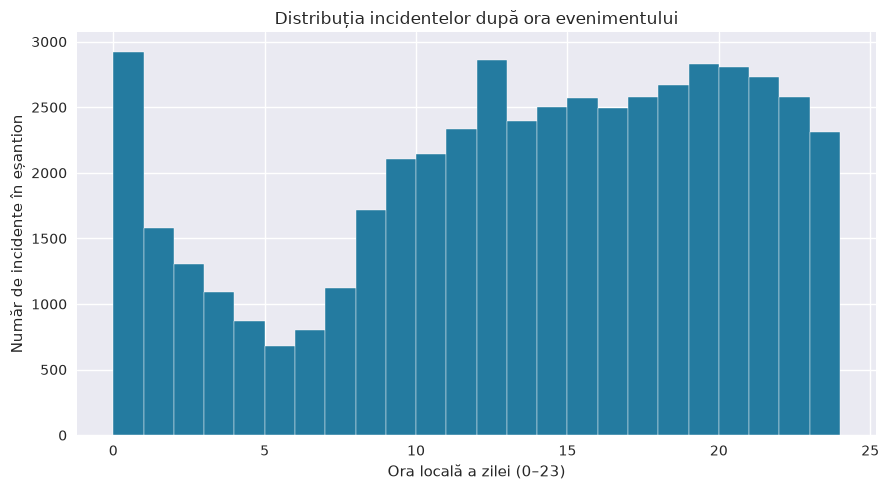

Interpretare: histograma evidențiază orele zilei cu volum mai ridicat în eșantionul aleator reproductibil.


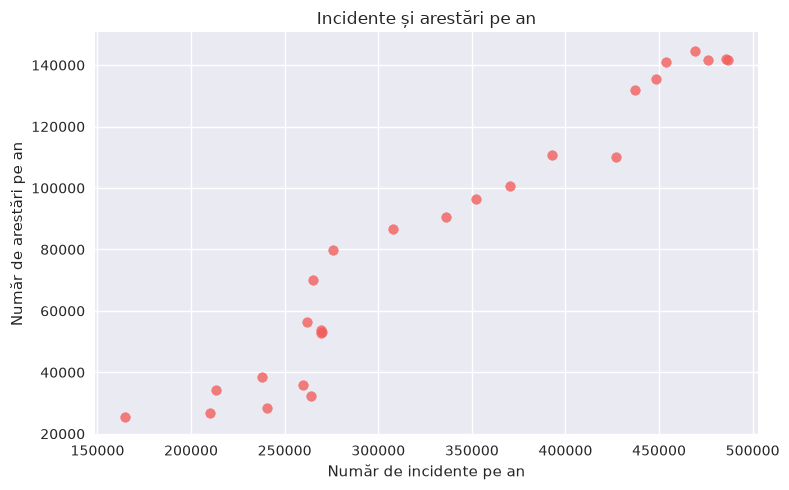

Interpretare: fiecare punct reprezintă un an; comparați volumul incidentelor cu numărul arestărilor, fără a interpreta corelația drept cauzalitate.


In [26]:
processed_df.createOrReplaceTempView('processed_crimes')

sql_counts_by_type = spark.sql('''
    SELECT `Primary Type` AS crime_type, COUNT(*) AS incident_count
    FROM processed_crimes
    GROUP BY `Primary Type`
    ORDER BY incident_count DESC
''')
sql_arrests_by_district = spark.sql('''
    SELECT District,
           COUNT(*) AS incident_count,
           SUM(arrest_count) AS arrests,
           ROUND(100.0 * SUM(arrest_count) / COUNT(*), 2) AS arrest_percent
    FROM processed_crimes
    WHERE District IS NOT NULL
    GROUP BY District
    ORDER BY arrests DESC
''')
sql_mean_hour_by_type = spark.sql('''
    SELECT `Primary Type` AS crime_type,
           ROUND(AVG(event_hour), 2) AS mean_event_hour,
           COUNT(*) AS incident_count
    FROM processed_crimes
    GROUP BY `Primary Type`
    ORDER BY incident_count DESC
''')

print('SQL 1: numărul incidentelor pe tip')
sql_counts_by_type.show(10, truncate=False)
print('SQL 2: incidente, arestări și rata arestărilor pe district')
sql_arrests_by_district.show(10, truncate=False)
print('SQL 3: ora medie a incidentelor pe tip')
sql_mean_hour_by_type.show(10, truncate=False)

top_type_row = sql_counts_by_type.first()
top_district_row = sql_arrests_by_district.first()
print(
    f'Concluzie bazată pe SQL: categoria cu cele mai multe incidente este '
    f'{top_type_row["crime_type"]} ({top_type_row["incident_count"]:,}); '
    f'districtul cu cele mai multe arestări este {top_district_row["District"]} '
    f'({top_district_row["arrests"]:,}).'
)

hour_sample = (
    processed_df.select('event_hour')
    .sample(withReplacement=False, fraction=0.01, seed=42)
    .limit(50000)
    .toPandas()
)
plt.figure(figsize=(9, 5))
plt.hist(hour_sample['event_hour'].dropna(), bins=24, range=(0, 24), color='#247ba0', edgecolor='white')
plt.title('Distribuția incidentelor după ora evenimentului')
plt.xlabel('Ora locală a zilei (0–23)')
plt.ylabel('Număr de incidente în eșantion')
plt.tight_layout()
plt.show()
print('Interpretare: histograma evidențiază orele zilei cu volum mai ridicat în eșantionul aleator reproductibil.')

year_aggregates = (
    processed_df.groupBy('Year')
    .agg(
        spark_functions.count('*').alias('incident_count'),
        spark_functions.sum('arrest_count').alias('arrest_count'),
    )
    .orderBy('Year')
    .toPandas()
    .dropna(subset=['Year'])
)
plt.figure(figsize=(8, 5))
plt.scatter(year_aggregates['incident_count'], year_aggregates['arrest_count'], color='#f25f5c', alpha=0.8)
plt.title('Incidente și arestări pe an')
plt.xlabel('Număr de incidente pe an')
plt.ylabel('Număr de arestări pe an')
plt.tight_layout()
plt.show()
print('Interpretare: fiecare punct reprezintă un an; comparați volumul incidentelor cu numărul arestărilor, fără a interpreta corelația drept cauzalitate.')

## Etapa 6: DWH și schema stea

Grain-ul tabelului de fapte este un rând pentru fiecare incident raportat. Măsurile aditive sunt `incident_count` (1 per fapt) și `arrest_count` (1 dacă a avut loc arestare, altfel 0). Cheile de tip și locație sunt hash-uri deterministe ale atributelor descriptive, iar `date_key` are formatul numeric `YYYYMMDD`.

```mermaid
erDiagram
    DIM_DATE ||--o{ FACT_CRIME : date_key
    DIM_CRIME_TYPE ||--o{ FACT_CRIME : crime_type_key
    DIM_LOCATION ||--o{ FACT_CRIME : location_key

    DIM_DATE {
        int date_key PK
        date full_date
        int year
        int month
        string weekday
    }
    DIM_CRIME_TYPE {
        string crime_type_key PK
        string primary_type
        string description
    }
    DIM_LOCATION {
        string location_key PK
        string district
        string beat
        int ward
        int community_area
    }
    FACT_CRIME {
        long incident_id PK
        int date_key FK
        string crime_type_key FK
        string location_key FK
        long incident_count
        long arrest_count
    }
}
```

In [27]:
from pyspark.sql import functions as spark_functions

DWH_ROOT = DATA_ROOT / 'dwh'

dwh_source = processed_delta_df
unknown_text = spark_functions.lit('Unknown')

location_fields = [
    spark_functions.coalesce(spark_functions.col('District').cast('string'), unknown_text).alias('district'),
    spark_functions.coalesce(spark_functions.col('Beat').cast('string'), unknown_text).alias('beat'),
    spark_functions.coalesce(spark_functions.col('Ward').cast('string'), unknown_text).alias('ward'),
    spark_functions.coalesce(spark_functions.col('Community Area').cast('string'), unknown_text).alias('community_area'),
]

dim_date = (
    dwh_source.select(spark_functions.col('event_date').alias('full_date')).distinct()
    .withColumn('date_key', spark_functions.date_format('full_date', 'yyyyMMdd').cast('int'))
    .withColumn('year', spark_functions.year('full_date'))
    .withColumn('month', spark_functions.month('full_date'))
    .withColumn('weekday', spark_functions.date_format('full_date', 'EEEE'))
    .select('date_key', 'full_date', 'year', 'month', 'weekday')
)

dim_crime_type = (
    dwh_source.select(
        spark_functions.coalesce(spark_functions.col('Primary Type'), unknown_text).alias('primary_type'),
        spark_functions.coalesce(spark_functions.col('Description'), unknown_text).alias('description'),
    )
    .distinct()
    .withColumn(
        'crime_type_key',
        spark_functions.sha2(spark_functions.concat_ws('||', 'primary_type', 'description'), 256),
    )
    .select('crime_type_key', 'primary_type', 'description')
)

dim_location = (
    dwh_source.select(*location_fields).distinct()
    .withColumn(
        'location_key',
        spark_functions.sha2(
            spark_functions.concat_ws('||', 'district', 'beat', 'ward', 'community_area'),
            256,
        ),
    )
    .select('location_key', 'district', 'beat', 'ward', 'community_area')
)

dwh_keyed_source = (
    dwh_source
    .withColumn('date_key', spark_functions.date_format('event_date', 'yyyyMMdd').cast('int'))
    .withColumn(
        'crime_type_key',
        spark_functions.sha2(
            spark_functions.concat_ws(
                '||',
                spark_functions.coalesce(spark_functions.col('Primary Type'), unknown_text),
                spark_functions.coalesce(spark_functions.col('Description'), unknown_text),
            ),
            256,
        ),
    )
    .withColumn(
        'location_key',
        spark_functions.sha2(
            spark_functions.concat_ws(
                '||',
                spark_functions.coalesce(spark_functions.col('District').cast('string'), unknown_text),
                spark_functions.coalesce(spark_functions.col('Beat').cast('string'), unknown_text),
                spark_functions.coalesce(spark_functions.col('Ward').cast('string'), unknown_text),
                spark_functions.coalesce(spark_functions.col('Community Area').cast('string'), unknown_text),
            ),
            256,
        ),
    )
)
fact_crime = dwh_keyed_source.select(
    spark_functions.col('ID').alias('incident_id'),
    'date_key',
    'crime_type_key',
    'location_key',
    spark_functions.col('Date').alias('event_timestamp'),
    spark_functions.col('Year').alias('event_year'),
    spark_functions.lit(1).cast('long').alias('incident_count'),
    spark_functions.col('arrest_count').cast('long').alias('arrest_count'),
)


def save_dwh_delta(dataframe, table_name):
    table_path = DWH_ROOT / table_name
    (
        dataframe.write.format('delta')
        .option('delta.columnMapping.mode', 'name')
        .option('delta.minReaderVersion', '2')
        .option('delta.minWriterVersion', '5')
        .mode('overwrite')
        .save(str(table_path))
    )
    return spark.read.format('delta').load(str(table_path))


dim_date = save_dwh_delta(dim_date, 'dim_date')
dim_crime_type = save_dwh_delta(dim_crime_type, 'dim_crime_type')
dim_location = save_dwh_delta(dim_location, 'dim_location')
fact_crime = save_dwh_delta(fact_crime, 'fact_crime')


def assert_unique_key(dataframe, key_name):
    duplicate_keys = (
        dataframe.groupBy(key_name).count()
        .filter(spark_functions.col('count') > 1)
        .limit(1)
        .count()
    )
    assert duplicate_keys == 0, f'Chei duplicate în {key_name}.'


for dimension, key_name in (
    (dim_date, 'date_key'),
    (dim_crime_type, 'crime_type_key'),
    (dim_location, 'location_key'),
):
    assert_unique_key(dimension, key_name)

orphan_date_count = fact_crime.join(dim_date.select('date_key'), 'date_key', 'left_anti').limit(1).count()
orphan_type_count = fact_crime.join(dim_crime_type.select('crime_type_key'), 'crime_type_key', 'left_anti').limit(1).count()
orphan_location_count = fact_crime.join(dim_location.select('location_key'), 'location_key', 'left_anti').limit(1).count()
assert orphan_date_count == orphan_type_count == orphan_location_count == 0
assert fact_crime.count() == processed_count

print('Rânduri DWH:')
for table_name, dataframe in (
    ('dim_date', dim_date),
    ('dim_crime_type', dim_crime_type),
    ('dim_location', dim_location),
    ('fact_crime', fact_crime),
):
    print(f'{table_name}: {dataframe.count():,}')
print('Cheile dimensiunilor sunt unice; referințe fără corespondent: 0.')

Rânduri DWH:
dim_date: 9,390
dim_crime_type: 614
dim_location: 2,464
fact_crime: 8,645,381
Cheile dimensiunilor sunt unice; referințe fără corespondent: 0.


In [28]:
assert_unique_key(fact_crime, 'incident_id')
print('Cheia primară incident_id este unică în tabelul de fapte.')

Cheia primară incident_id este unică în tabelul de fapte.


### Operații OLAP

Întrebările sunt distincte: evoluția anuală a volumului (roll-up), detalierea lunară (drill-down), distribuția unui singur tip pe district (slice) și distribuția pe tip într-un district și interval de ani selectate simultan (dice).

In [29]:
fact_crime.createOrReplaceTempView('fact_crime')
dim_date.createOrReplaceTempView('dim_date')
dim_crime_type.createOrReplaceTempView('dim_crime_type')
dim_location.createOrReplaceTempView('dim_location')

roll_up_result = spark.sql('''
    SELECT date_dimension.year,
           SUM(fact.incident_count) AS incidents,
           SUM(fact.arrest_count) AS arrests
    FROM fact_crime fact
    JOIN dim_date date_dimension USING (date_key)
    GROUP BY date_dimension.year
    ORDER BY date_dimension.year
''')
print('ROLL-UP — Câte incidente și arestări au fost înregistrate în fiecare an?')
roll_up_result.show(30, truncate=False)

selected_rollup_year = roll_up_result.orderBy(spark_functions.desc('year')).first()['year']
drill_down_result = spark.sql(f'''
    SELECT date_dimension.year,
           date_dimension.month,
           SUM(fact.incident_count) AS incidents,
           SUM(fact.arrest_count) AS arrests
    FROM fact_crime fact
    JOIN dim_date date_dimension USING (date_key)
    WHERE date_dimension.year = {int(selected_rollup_year)}
    GROUP BY date_dimension.year, date_dimension.month
    ORDER BY date_dimension.month
''')
print(f'DRILL-DOWN — Cum se distribuie lunar activitatea în anul {selected_rollup_year}?')
drill_down_result.show(12, truncate=False)

selected_crime_type = sql_counts_by_type.first()['crime_type']
escaped_crime_type = selected_crime_type.replace("'", "''")
slice_result = spark.sql(f'''
    SELECT location.district,
           SUM(fact.incident_count) AS incidents,
           SUM(fact.arrest_count) AS arrests
    FROM fact_crime fact
    JOIN dim_crime_type crime_type USING (crime_type_key)
    JOIN dim_location location USING (location_key)
    WHERE crime_type.primary_type = '{escaped_crime_type}'
      AND location.district <> 'Unknown'
    GROUP BY location.district
    ORDER BY incidents DESC
''')
print(f'SLICE — În ce districte apare tipul {selected_crime_type}?')
slice_result.show(20, truncate=False)

selected_district = sql_arrests_by_district.first()['District']
escaped_district = selected_district.replace("'", "''")
latest_year = int(dim_date.agg(spark_functions.max('year')).first()[0])
dice_start_year = 2001 if latest_year - 2 < 2001 else latest_year - 2
dice_result = spark.sql(f'''
    SELECT crime_type.primary_type,
           SUM(fact.incident_count) AS incidents,
           SUM(fact.arrest_count) AS arrests
    FROM fact_crime fact
    JOIN dim_date date_dimension USING (date_key)
    JOIN dim_location location USING (location_key)
    JOIN dim_crime_type crime_type USING (crime_type_key)
    WHERE date_dimension.year BETWEEN {dice_start_year} AND {latest_year}
      AND location.district = '{escaped_district}'
    GROUP BY crime_type.primary_type
    ORDER BY incidents DESC
''')
print(
    f'DICE — Ce tipuri de incidente apar în districtul {selected_district}, '
    f'în intervalul {dice_start_year}–{latest_year}?'
)
dice_result.show(20, truncate=False)

print(
    f'Interpretare: roll-up-ul însumează {int(roll_up_result.agg(spark_functions.sum("incidents")).first()[0]):,} incidente; '
    f'drill-down-ul detaliază anul {selected_rollup_year}; slice-ul fixează tipul '
    f'{selected_crime_type}; dice-ul restrânge simultan districtul și intervalul de ani.'
)

ROLL-UP — Câte incidente și arestări au fost înregistrate în fiecare an?


+----+---------+-------+
|year|incidents|arrests|
+----+---------+-------+
|2001|485964   |141945 |
|2002|486832   |141573 |
|2003|476006   |141601 |
|2004|469440   |144704 |
|2005|453803   |140929 |
|2006|448211   |135431 |
|2007|437117   |131885 |
|2008|427212   |110027 |
|2009|392864   |110853 |
|2010|370568   |100561 |
|2011|352052   |96303  |
|2012|336394   |90696  |
|2013|307637   |86579  |
|2014|275907   |79671  |
|2015|264943   |70083  |
|2016|270032   |53087  |
|2017|269350   |52709  |
|2018|269240   |53931  |
|2019|261935   |56318  |
|2020|213068   |34226  |
|2021|209999   |26671  |
|2022|240492   |28281  |
|2023|263843   |32218  |
|2024|259631   |35891  |
|2025|238083   |38363  |
|2026|164758   |25503  |
+----+---------+-------+

DRILL-DOWN — Cum se distribuie lunar activitatea în anul 2026?


+----+-----+---------+-------+
|year|month|incidents|arrests|
+----+-----+---------+-------+
|2026|1    |17023    |2853   |
|2026|2    |16540    |2742   |
|2026|3    |19175    |2977   |
|2026|4    |19136    |2901   |
|2026|5    |21137    |2978   |
|2026|6    |20024    |3107   |
|2026|7    |21222    |3326   |
|2026|8    |20680    |3134   |
|2026|9    |9821     |1485   |
+----+-----+---------+-------+



SLICE — În ce districte apare tipul THEFT?


+--------+---------+-------+
|district|incidents|arrests|
+--------+---------+-------+
|018     |165034   |19852  |
|001     |153254   |24733  |
|019     |135726   |12727  |
|012     |125396   |9999   |
|008     |112603   |13724  |
|014     |97102    |7720   |
|025     |91379    |15159  |
|006     |86804    |12904  |
|002     |83231    |8346   |
|004     |78431    |6408   |
|009     |75806    |9230   |
|016     |68746    |4776   |
|003     |65598    |6156   |
|007     |64501    |4796   |
|024     |63344    |6586   |
|017     |63290    |7830   |
|011     |61557    |5169   |
|010     |54678    |4779   |
|022     |54356    |4586   |
|005     |53036    |4786   |
+--------+---------+-------+
only showing top 20 rows


DICE — Ce tipuri de incidente apar în districtul 011, în intervalul 2024–2026?


+--------------------------------+---------+-------+
|primary_type                    |incidents|arrests|
+--------------------------------+---------+-------+
|BATTERY                         |7326     |1188   |
|NARCOTICS                       |5540     |5477   |
|THEFT                           |3973     |94     |
|CRIMINAL DAMAGE                 |3557     |176    |
|ASSAULT                         |3398     |353    |
|MOTOR VEHICLE THEFT             |2512     |162    |
|OTHER OFFENSE                   |2063     |391    |
|ROBBERY                         |1441     |71     |
|WEAPONS VIOLATION               |1432     |1081   |
|DECEPTIVE PRACTICE              |1111     |43     |
|BURGLARY                        |904      |33     |
|CRIMINAL TRESPASS               |547      |173    |
|PROSTITUTION                    |288      |282    |
|OFFENSE INVOLVING CHILDREN      |258      |27     |
|CRIMINAL SEXUAL ASSAULT         |235      |6      |
|PUBLIC PEACE VIOLATION          |223      |12

## Etapa 7: Replay DWH → Kafka → Spark Structured Streaming → MongoDB

Datele istorice din DWH sunt redate cu pauze între loturi, deci fluxul este o simulare: o sursă live ar publica evenimente la momentul producerii lor. Kafka decuplează producerul de consumatori, păstrează mesajele și permite reluarea lor; fără el, producerul și procesarea ar fi strâns cuplate, iar vârfurile de volum și întreruperile ar fi mai greu de gestionat. Simularea nu reproduce latența reală a sursei, duplicatele/reordonarea din rețea, autentificarea, retenția la scară sau garanțiile end-to-end.

Eșantionul include primele trei zile distincte disponibile, câte cel mult 250 de incidente pe zi; fereastra de agregare este tumbling de o zi UTC, cu numărul de incidente și arestări. Data de eveniment este validată înainte de DWH. Dacă o sursă viitoare furnizează un timestamp lipsă, producerul generează determinist unul pornind de la `incident_id` și marchează mesajul cu `timestamp_is_synthetic=True`.

Pentru demonstrarea actualizării dashboardului, rulați celula inițială de streaming, porniți Streamlit într-un terminal separat, apoi rulați celula „Lot suplimentar” și apăsați „Reîncarcă datele” în dashboard.

Eșantion DWH: 750 incidente, maximum 250 pentru fiecare dintre zilele [datetime.date(2001, 1, 1), datetime.date(2001, 1, 2), datetime.date(2001, 1, 3)].
Lot Kafka publicat: 250 mesaje; total=250.
Lot Kafka publicat: 250 mesaje; total=500.
Lot Kafka publicat: 250 mesaje; total=750.
Exemplu mesaj Kafka:
{
  "incident_id": 1309885,
  "event_timestamp": "2001-01-01T00:00:00Z",
  "primary_type": "CRIMINAL DAMAGE",
  "district": "019",
  "arrest_count": 0,
  "timestamp_is_synthetic": false
}


26/10/09 09:55:42 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
26/10/09 09:55:42 WARN MicroBatchExecution: Disabling AQE since AQE is not supported in stateful workloads.
26/10/09 09:56:06 WARN ProcessingTimeExecutor: Current batch is falling behind. The trigger interval is 2000 milliseconds, but spent 23842 milliseconds
26/10/09 09:56:06 WARN DAGScheduler: Failed to cancel job group b6e7081b-65a1-4370-98b3-61b31ec8c9dc. Cannot find active jobs for it.
26/10/09 09:56:06 WARN DAGScheduler: Failed to cancel job group b6e7081b-65a1-4370-98b3-61b31ec8c9dc. Cannot find active jobs for it.


Ferestre persistate în MongoDB: 3
2001-01-01T00:00:00 – 2001-01-02T00:00:00: incidente=250, arestări=41
2001-01-02T00:00:00 – 2001-01-03T00:00:00: incidente=250, arestări=49
2001-01-03T00:00:00 – 2001-01-04T00:00:00: incidente=250, arestări=26


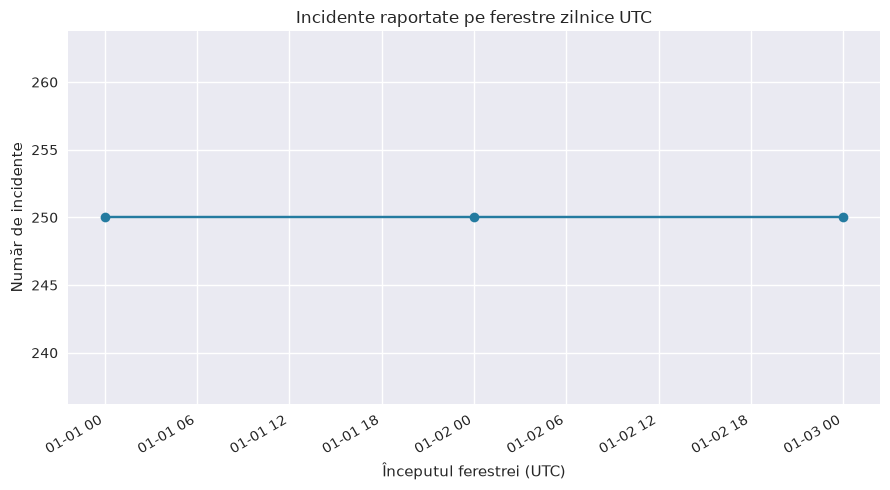

Interpretare grafic: fereastra cu cel mai mare volum începe la 2001-01-01T00:00:00 și conține 250 incidente.
Concluzie 1: vârful de 250 incidente dintr-o fereastră poate justifica alocarea temporară a resurselor de analiză pentru perioada respectivă.
Concluzie 2: în cele 3 ferestre, rata arestărilor este 15.5% (116/750); utilizatorul poate compara indicatorul pe perioade înainte de a modifica planificarea.


In [32]:
import json
import builtins
import time
from datetime import timezone, timedelta
from uuid import uuid4

from kafka import KafkaProducer
from pymongo import MongoClient
from pyspark.sql import functions as spark_functions
from pyspark.sql import types as spark_types
from pyspark.sql.window import Window as SparkWindow

spark.conf.set('spark.sql.session.timeZone', 'UTC')
KAFKA_BOOTSTRAP_SERVERS = os.environ.get('KAFKA_BOOTSTRAP_SERVERS', 'kafka:9092')
MONGODB_URI = os.environ.get('MONGODB_URI', 'mongodb://mongodb:27017')
MONGODB_DATABASE = os.environ.get('MONGODB_DATABASE', 'bigdata')
MONGODB_COLLECTION = os.environ.get('MONGODB_COLLECTION', 'crime_windows')
KAFKA_TOPIC = f'chicago-crime-demo-{uuid4().hex[:10]}'
STREAM_BATCH_SIZE = 250

# Producerul citește exclusiv fapte din DWH și limitează demo-ul la trei zile.
dwh_stream_source = (
    fact_crime
    .join(dim_date, 'date_key')
    .join(dim_crime_type, 'crime_type_key')
    .join(dim_location, 'location_key')
    .select(
        'incident_id',
        'event_timestamp',
        'primary_type',
        'district',
        'arrest_count',
    )
)
stream_dates = (
    dwh_stream_source
    .select(spark_functions.to_date('event_timestamp').alias('event_day'))
    .where(spark_functions.col('event_day').isNotNull())
    .distinct()
    .orderBy('event_day')
    .limit(3)
    .collect()
)
selected_stream_dates = [row['event_day'] for row in stream_dates]
if len(selected_stream_dates) < 3:
    raise ValueError('Streaming-ul demonstrativ necesită cel puțin trei zile distincte în DWH.')

stream_sample = (
    dwh_stream_source
    .withColumn('event_day', spark_functions.to_date('event_timestamp'))
    .filter(spark_functions.col('event_day').isin(selected_stream_dates))
    .withColumn(
        'sample_rank',
        spark_functions.row_number().over(
            SparkWindow.partitionBy('event_day').orderBy('incident_id')
        ),
    )
    .filter(spark_functions.col('sample_rank') <= STREAM_BATCH_SIZE)
    .orderBy('event_timestamp', 'incident_id')
    .drop('event_day', 'sample_rank')
    .cache()
)
stream_sample_count = stream_sample.count()
print(
    f'Eșantion DWH: {stream_sample_count:,} incidente, maximum '
    f'{STREAM_BATCH_SIZE} pentru fiecare dintre zilele {selected_stream_dates}.'
)


def make_stream_payload(stream_row):
    event_timestamp = stream_row['event_timestamp']
    timestamp_is_synthetic = event_timestamp is None
    if timestamp_is_synthetic:
        event_timestamp = datetime(2000, 1, 1) + timedelta(seconds=int(stream_row['incident_id']) % 86400)
    if event_timestamp.tzinfo is None:
        event_timestamp = event_timestamp.replace(tzinfo=timezone.utc)
    else:
        event_timestamp = event_timestamp.astimezone(timezone.utc)
    return {
        'incident_id': int(stream_row['incident_id']),
        'event_timestamp': event_timestamp.isoformat().replace('+00:00', 'Z'),
        'primary_type': stream_row['primary_type'] or 'Unknown',
        'district': stream_row['district'] or 'Unknown',
        'arrest_count': int(stream_row['arrest_count'] or 0),
        'timestamp_is_synthetic': timestamp_is_synthetic,
    }


producer = KafkaProducer(
    bootstrap_servers=KAFKA_BOOTSTRAP_SERVERS,
    value_serializer=lambda payload: json.dumps(payload).encode('utf-8'),
    acks='all',
    retries=3,
)
first_kafka_message = None
published_count = 0
batch_count = 0
try:
    for stream_row in stream_sample.toLocalIterator():
        payload = make_stream_payload(stream_row)
        if first_kafka_message is None:
            first_kafka_message = payload
        producer.send(KAFKA_TOPIC, value=payload)
        published_count += 1
        batch_count += 1
        if batch_count == STREAM_BATCH_SIZE:
            producer.flush()
            print(f'Lot Kafka publicat: {batch_count} mesaje; total={published_count}.')
            batch_count = 0
            time.sleep(0.5)
    if batch_count:
        producer.flush()
        print(f'Lot Kafka publicat: {batch_count} mesaje; total={published_count}.')
finally:
    producer.close()
stream_sample.unpersist()
print('Exemplu mesaj Kafka:')
print(json.dumps(first_kafka_message, ensure_ascii=False, indent=2))

stream_event_schema = spark_types.StructType([
    spark_types.StructField('incident_id', spark_types.LongType(), False),
    spark_types.StructField('event_timestamp', spark_types.TimestampType(), False),
    spark_types.StructField('primary_type', spark_types.StringType(), True),
    spark_types.StructField('district', spark_types.StringType(), True),
    spark_types.StructField('arrest_count', spark_types.LongType(), False),
    spark_types.StructField('timestamp_is_synthetic', spark_types.BooleanType(), False),
])
stream_events = (
    spark.readStream.format('kafka')
    .option('kafka.bootstrap.servers', KAFKA_BOOTSTRAP_SERVERS)
    .option('subscribe', KAFKA_TOPIC)
    .option('startingOffsets', 'earliest')
    .option('failOnDataLoss', 'false')
    .load()
    .select(
        spark_functions.from_json(
            spark_functions.col('value').cast('string'),
            stream_event_schema,
        ).alias('event')
    )
    .select('event.*')
)
windowed_metrics = (
    stream_events
    .groupBy(spark_functions.window('event_timestamp', '1 day'))
    .agg(
        spark_functions.count('*').alias('incident_count'),
        spark_functions.sum('arrest_count').alias('arrest_count'),
        spark_functions.sum(
            spark_functions.when(spark_functions.col('timestamp_is_synthetic'), 1).otherwise(0)
        ).alias('synthetic_timestamp_count'),
    )
    .select(
        spark_functions.col('window.start').alias('window_start'),
        spark_functions.col('window.end').alias('window_end'),
        'incident_count',
        'arrest_count',
        'synthetic_timestamp_count',
    )
)

mongo_stream_client = MongoClient(MONGODB_URI, serverSelectionTimeoutMS=5000)
mongo_stream_client.admin.command('ping')
window_collection = mongo_stream_client[MONGODB_DATABASE][MONGODB_COLLECTION]
window_collection.create_index('window_start')


def save_window_batch(batch_dataframe, batch_id):
    for window_row in batch_dataframe.toLocalIterator():
        window_start = window_row['window_start']
        window_end = window_row['window_end']
        if window_start.tzinfo is None:
            window_start = window_start.replace(tzinfo=timezone.utc)
            window_end = window_end.replace(tzinfo=timezone.utc)
        window_id = window_start.isoformat()
        window_document = {
            '_id': window_id,
            'window_start': window_start,
            'window_end': window_end,
            'incident_count': int(window_row['incident_count']),
            'arrest_count': int(window_row['arrest_count'] or 0),
            'synthetic_timestamp_count': int(window_row['synthetic_timestamp_count'] or 0),
            'source_topic': KAFKA_TOPIC,
            'batch_id': int(batch_id),
        }
        window_collection.replace_one({'_id': window_id}, window_document, upsert=True)


checkpoint_path = DATA_ROOT / 'streaming_checkpoints' / KAFKA_TOPIC
stream_query = (
    windowed_metrics.writeStream
    .outputMode('update')
    .foreachBatch(save_window_batch)
    .option('checkpointLocation', str(checkpoint_path))
    .trigger(processingTime='2 seconds')
    .start()
)
try:
    stream_query.processAllAvailable()
finally:
    stream_query.stop()
    stream_query.awaitTermination()

expected_window_ids = [
    datetime.combine(event_day, datetime.min.time(), tzinfo=timezone.utc).isoformat()
    for event_day in selected_stream_dates
]
window_documents = list(
    window_collection.find({'_id': {'$in': expected_window_ids}})
    .sort('window_start', 1)
)
assert len(window_documents) >= 3, 'Nu au fost persistate cel puțin trei ferestre în MongoDB.'
print(f'Ferestre persistate în MongoDB: {len(window_documents)}')
for window_document in window_documents:
    print(
        f"{window_document['window_start'].isoformat()} – "
        f"{window_document['window_end'].isoformat()}: "
        f"incidente={window_document['incident_count']}, "
        f"arestări={window_document['arrest_count']}"
    )

window_plot_data = pd.DataFrame(window_documents).sort_values('window_start')
plt.figure(figsize=(9, 5))
plt.plot(
    window_plot_data['window_start'],
    window_plot_data['incident_count'],
    marker='o',
    color='#247ba0',
)
plt.title('Incidente raportate pe ferestre zilnice UTC')
plt.xlabel('Începutul ferestrei (UTC)')
plt.ylabel('Număr de incidente')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

peak_window = builtins.max(window_documents, key=lambda document: document['incident_count'])
total_window_incidents = builtins.sum(document['incident_count'] for document in window_documents)
total_window_arrests = builtins.sum(document['arrest_count'] for document in window_documents)
window_arrest_rate = 100 * total_window_arrests / total_window_incidents if total_window_incidents else 0.0
print(
    f"Interpretare grafic: fereastra cu cel mai mare volum începe la "
    f"{peak_window['window_start'].isoformat()} și conține {peak_window['incident_count']:,} incidente."
)
print(
    f"Concluzie 1: vârful de {peak_window['incident_count']:,} incidente dintr-o fereastră "
    'poate justifica alocarea temporară a resurselor de analiză pentru perioada respectivă.'
)
print(
    f'Concluzie 2: în cele {len(window_documents)} ferestre, rata arestărilor este '
    f'{window_arrest_rate:.1f}% ({total_window_arrests:,}/{total_window_incidents:,}); '
    'utilizatorul poate compara indicatorul pe perioade înainte de a modifica planificarea.'
)
mongo_stream_client.close()

### Lot suplimentar pentru validarea refresh-ului dashboardului

Celula publică incidente diferite de eșantionul inițial pe același topic. Spark reia procesarea cu același checkpoint, iar documentele MongoDB pentru ferestrele afectate sunt actualizate prin upsert idempotent. Lăsați dashboardul deschis și reîncărcați după rularea celulei.

In [ ]:
import builtins
FOLLOWUP_BATCH_SIZE = 100
followup_sample = (
    dwh_stream_source
    .withColumn('event_day', spark_functions.to_date('event_timestamp'))
    .filter(spark_functions.col('event_day').isin(selected_stream_dates))
    .withColumn(
        'sample_rank',
        spark_functions.row_number().over(
            SparkWindow.partitionBy('event_day').orderBy('incident_id')
        ),
    )
    .filter(
        (spark_functions.col('sample_rank') > STREAM_BATCH_SIZE)
        & (spark_functions.col('sample_rank') <= STREAM_BATCH_SIZE + FOLLOWUP_BATCH_SIZE)
    )
    .orderBy('event_timestamp', 'incident_id')
    .drop('event_day', 'sample_rank')
    .cache()
)
followup_count = followup_sample.count()
if followup_count == 0:
    raise ValueError(
        'Nu există suficiente incidente în zilele selectate pentru lotul suplimentar; '
        'alegeți alte zile în stream_dates.'
    )
print(f'Lot suplimentar selectat din DWH: {followup_count:,} incidente.')

followup_producer = KafkaProducer(
    bootstrap_servers=KAFKA_BOOTSTRAP_SERVERS,
    value_serializer=lambda payload: json.dumps(payload).encode('utf-8'),
    acks='all',
    retries=3,
)
followup_published = 0
followup_batch_count = 0
try:
    for stream_row in followup_sample.toLocalIterator():
        payload = make_stream_payload(stream_row)
        if followup_published == 0:
            print('Exemplu mesaj din lotul suplimentar:')
            print(json.dumps(payload, ensure_ascii=False, indent=2))
        followup_producer.send(KAFKA_TOPIC, value=payload)
        followup_published += 1
        followup_batch_count += 1
        if followup_batch_count == FOLLOWUP_BATCH_SIZE:
            followup_producer.flush()
            print(f'Lot suplimentar Kafka publicat: {followup_batch_count} mesaje.')
            followup_batch_count = 0
            time.sleep(0.5)
    if followup_batch_count:
        followup_producer.flush()
        print(f'Lot suplimentar Kafka publicat: {followup_batch_count} mesaje.')
finally:
    followup_producer.close()
    followup_sample.unpersist()

followup_mongo_client = MongoClient(MONGODB_URI, serverSelectionTimeoutMS=5000)
followup_mongo_client.admin.command('ping')
followup_collection = followup_mongo_client[MONGODB_DATABASE][MONGODB_COLLECTION]


def save_followup_window_batch(batch_dataframe, batch_id):
    for window_row in batch_dataframe.toLocalIterator():
        window_start = window_row['window_start']
        window_end = window_row['window_end']
        if window_start.tzinfo is None:
            window_start = window_start.replace(tzinfo=timezone.utc)
            window_end = window_end.replace(tzinfo=timezone.utc)
        window_id = window_start.isoformat()
        followup_collection.replace_one(
            {'_id': window_id},
            {
                '_id': window_id,
                'window_start': window_start,
                'window_end': window_end,
                'incident_count': int(window_row['incident_count']),
                'arrest_count': int(window_row['arrest_count'] or 0),
                'synthetic_timestamp_count': int(window_row['synthetic_timestamp_count'] or 0),
                'source_topic': KAFKA_TOPIC,
                'batch_id': int(batch_id),
            },
            upsert=True,
        )


followup_query = (
    windowed_metrics.writeStream
    .outputMode('update')
    .foreachBatch(save_followup_window_batch)
    .option('checkpointLocation', str(checkpoint_path))
    .trigger(processingTime='2 seconds')
    .start()
)
try:
    followup_query.processAllAvailable()
finally:
    followup_query.stop()
    followup_query.awaitTermination()

updated_window_documents = list(
    followup_collection.find({'_id': {'$in': expected_window_ids}})
    .sort('window_start', 1)
)

ERROR:tornado.general:Uncaught exception in ZMQStream callback      (0 + 4) / 6]
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/site-packages/zmq/eventloop/zmqstream.py", line 566, in _log_error
    f.result()
  File "/usr/local/lib/python3.12/site-packages/ipykernel/kernelbase.py", line 584, in shell_channel_thread_main
    _, msg2 = self.session.feed_identities(msg, copy=False)
              ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/site-packages/jupyter_client/session.py", line 998, in feed_identities
    raise ValueError(msg)
ValueError: DELIM not in msg_list
ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/site-packages/zmq/eventloop/zmqstream.py", line 566, in _log_error
    f.result()
  File "/usr/local/lib/python3.12/site-packages/ipykernel/kernelbase.py", line 584, in shell_channel_thread_main
    _, msg2 = self.session.feed_identities(

Lot suplimentar selectat din DWH: 300 incidente.
Exemplu mesaj din lotul suplimentar:
{
  "incident_id": 1311351,
  "event_timestamp": "2001-01-01T00:00:00Z",
  "primary_type": "BURGLARY",
  "district": "009",
  "arrest_count": 0,
  "timestamp_is_synthetic": false
}
Lot suplimentar Kafka publicat: 100 mesaje.
Lot suplimentar Kafka publicat: 100 mesaje.
Lot suplimentar Kafka publicat: 100 mesaje.


26/10/09 09:57:02 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
26/10/09 09:57:02 WARN MicroBatchExecution: Disabling AQE since AQE is not supported in stateful workloads.
26/10/09 09:57:03 WARN HDFSBackedStateStoreProvider StateStoreProviderId[ storeId=StateStoreId[ operatorId=0, partitionId=0, storeName=default ], queryRunId=a6206a05-b209-4668-86b6-08f6161c9f2c ]: The state for version 1 doesn't exist in loadedMaps. Reading snapshot file and delta files if needed...Note that this is normal for the first batch of starting query.
26/10/09 09:57:03 WARN HDFSBackedStateStoreProvider StateStoreProviderId[ storeId=StateStoreId[ operatorId=0, partitionId=1, storeName=default ], queryRunId=a6206a05-b209-4668-86b6-08f6161c9f2c ]: The state for version 1 doesn't exist in loadedMaps. Reading snapshot file and delta files if needed...Note that this is normal for the first batch of starting query.
26/10/09 09:57:03 WA

PySparkTypeError: [NOT_EXPECTED_TYPE] Argument `col` should be Column or str, got generator.

Bad pipe message: %s [b"\xc5+R\xc6rb\xf5\x96R\xf8\xc8\\f\xb1\xd8\x15\xec\xb9\x00\x00\x84\x003\x009\x005\x00/\xc0,\xc00\x00\xa3\x00\x9f\xcc\xa9\xcc\xa8\xcc\xaa\xc0\xaf\xc0\xad\xc0\xa3\xc0\x9f\xc0+\xc0/\x00\xa2\x00\x9e\xc0\xae\xc0\xac\xc0\xa2\xc0\x9e\xc0$\xc0(\x00k\x00j\xc0s\xc0w\x00\xc4\x00\xc3\xc0#\xc0'\x00g\x00@\xc0r\xc0v\x00\xbe\x00\xbd\xc0\n\xc0\x14\x008\x00\x88\x00\x87\xc0\t\xc0\x13\x002\x00\x9a\x00\x99\x00E\x00D\x00\x9d\xc0\xa1\xc0\x9d\x00\x9c\xc0\xa0\xc0\x9c\x00=\x00\xc0\x00<\x00\xba\x00\x84\x00\x96\x00A\x00\x07\x00\xff\x01\x00\x00F\x00\x0b\x00\x04\x03\x00\x01\x02\x00\n\x00\n\x00\x08\x00\x1d\x00\x17\x00\x19\x00\x18\x00#\x00\x00\x00\x16\x00\x00\x00\x17\x00\x00\x00\r\x00 \x00\x1e\x06\x01\x06\x02\x06\x03\x05\x01\x05\x02\x05\x03\x04\x01\x04\x02\x04\x03\x03\x01\x03", b'\x03', b'\x02', b'\x03']
Bad pipe message: %s [b'']
Bad pipe message: %s [b'\x86\xa6\xce\xa5\xc5\xf4^Z\x89\x10!', b'-\xc4\xfb\x00\x00\x80\x00\x1d\x00\x1c\xfe\xff\xfe\xfe\x00c\x00e\x00\x11\x00r\x00\x13\x00s\x002\x00@\x00

In [34]:
before_incident_total = builtins.sum(document['incident_count'] for document in window_documents)
after_incident_total = builtins.sum(document['incident_count'] for document in updated_window_documents)
assert len(updated_window_documents) >= 3
assert after_incident_total > before_incident_total, 'Dashboardul nu ar afișa o valoare modificată după lot.'
print(
    f'Verificare refresh: incidentele din cele trei ferestre au crescut '
    f'de la {before_incident_total:,} la {after_incident_total:,} după lotul nou.'
)
followup_mongo_client.close()

Verificare refresh: incidentele din cele trei ferestre au crescut de la 750 la 1,050 după lotul nou.


In [ ]:
# Oprirea sesiunii Spark
spark.stop()
print("Sesiunea Spark a fost oprită.")

Sesiunea Spark a fost oprită.


26/10/09 10:01:02 WARN StateStore: Error running maintenance thread
java.lang.IllegalStateException: SparkEnv not active, cannot do maintenance on StateStores
	at org.apache.spark.sql.execution.streaming.state.StateStore$.doMaintenance(StateStore.scala:1644)
	at org.apache.spark.sql.execution.streaming.state.StateStore$.$anonfun$startMaintenanceIfNeeded$1(StateStore.scala:1596)
	at org.apache.spark.sql.execution.streaming.state.StateStore$MaintenanceTask$$anon$1.run(StateStore.scala:1278)
	at java.base/java.util.concurrent.Executors$RunnableAdapter.call(Executors.java:572)
	at java.base/java.util.concurrent.FutureTask.runAndReset(FutureTask.java:358)
	at java.base/java.util.concurrent.ScheduledThreadPoolExecutor$ScheduledFutureTask.run(ScheduledThreadPoolExecutor.java:305)
	at java.base/java.util.concurrent.ThreadPoolExecutor.runWorker(ThreadPoolExecutor.java:1144)
	at java.base/java.util.concurrent.ThreadPoolExecutor$Worker.run(ThreadPoolExecutor.java:642)
	at java.base/java.lang.Thre